# Seq2Seq Chatbot with Luong Attention

This notebook builds a chatbot that learns to reply from movie dialogue. It re-implements the PyTorch [Chatbot Tutorial](https://pytorch.org/tutorials/beginner/chatbot_tutorial.html) by Matthew Inkawhich and trains on the [Cornell Movie-Dialogs Corpus](https://www.cs.cornell.edu/~cristian/Cornell_Movie-Dialogs_Corpus.html).

The model is a sequence-to-sequence (seq2seq) network. A GRU **encoder** reads the input sentence. A GRU **decoder** with **Luong attention** writes the reply one word at a time.

## Pipeline

```
utterances.jsonl  (304,713 lines of dialogue)
   │  1. pair every line with the next line
   ▼
221,282 sentence pairs ──► the last 10% (other movies) are held out for validation and test
   │  2. first 90%: clean the text, filter by length, replace rare words with UNK, build the vocabulary
   ▼
58,118 training pairs + a vocabulary of 7,311 words
   │  3. pad and stack into batch tensors
   ▼
input (L, B), lengths (B,), target (L', B), mask (L', B)
   │
   ├──► 4. encoder: bidirectional GRU ──► outputs (L, B, H), hidden (4, B, H)
   │                                          │
   │         previous word (1, B) ──► 5. decoder GRU (one step) + attention
   │                                          │
   │                                  word probabilities (B, V)
   │                     ┌────────────────────┴────────────────────┐
   ▼                     ▼                                         ▼
          6. training step: loss and backpropagation   7. inference: search for the best reply
             next input = the correct word                next input = its own output

8. validation: an LLM judge scores the chatbot's replies to held-out sentences
9. training loop: train, validate every 200 iterations, draw a chart
10. run: build the model, train, chat, final test
```

## Notation

| Symbol | Meaning | Value |
| --- | --- | --- |
| `L` | words in the longest sentence of a batch, including EOS | at most 10 |
| `B` | sentences in a batch | 64 in training |
| `H` | hidden size of the GRUs | 500 |
| `V` | vocabulary size, including PAD, SOS, EOS and UNK | 7,311 |


## Source and changes

The data pipeline, the model and the figures come from the PyTorch Chatbot Tutorial. That tutorial borrows code from:

- Yuan-Kuei Wu's pytorch-chatbot: <https://github.com/ywk991112/pytorch-chatbot>
- Sean Robertson's practical-pytorch seq2seq-translation example: <https://github.com/spro/practical-pytorch/tree/master/seq2seq-translation>
- FloydHub's Cornell Movie Corpus preprocessing code: <https://github.com/floydhub/textutil-preprocess-cornell-movie-corpus>

These parts are different from the tutorial:

| Where | Tutorial | This notebook | Why |
| --- | --- | --- | --- |
| Everywhere | camelCase names, such as `loadLinesAndConversations` | `snake_case` names | PEP 8 |
| 1.1, 1.2 | `encoding='iso-8859-1'` | `encoding='utf-8'` | `utterances.jsonl` is pure ASCII, so the result is the same |
| 1.2 | dict keys `lineID`, `characterID`, `conversationID`, `movieID` | `line_id`, `character_id`, `conversation_id`, `movie_id` | Same naming rule |
| 2.2 | `readVocs` returns an empty `Voc` and the pairs | `read_pairs` returns only the pairs; `build_voc` creates and fills the `Voc` | One function, one job |
| 2.2 | `loadPrepareData(corpus, corpus_name, datafile, save_dir)` | `load_prepare_data(corpus_name, data_file)` | Two parameters were never used |
| 2.2 | All pairs are used for training | Only the first 90% of the pairs (by movie); the rest is held out | Validation and test need unseen movies |
| 4.1, 5.2 | `nn.GRU(hidden_size, hidden_size, ...)` | `nn.GRU(embedding.embedding_dim, hidden_size, ...)` | The first argument is the word-vector size, not the state size |
| 2.3, 3.1, 7.1 | A pair that contains a rare word is removed, and an input with an unknown word gets no reply | A rare or unknown word becomes the word `UNK` and the pair is kept; the bot never writes `UNK`. `USE_UNK = False` gives the tutorial's behaviour | 18% of the training pairs were lost, and 16% of the validation sentences got no reply |
| 7.2 | Words written after the first `EOS` stay in the reply | `evaluate` keeps only the words before the first `EOS` | The loss masks every position after `EOS`, so the model never learned what to write there |
| 7.3 | Greedy search only | Sampling and beam search are added. The default is beam search (width 10) with a score that lowers replies made of very common words | Greedy replies are generic: three replies were 81 of the 200 replies |
| 8, 9 | The training loop prints the training loss only | Every `validate_every` iterations an LLM judge scores the replies to held-out sentences; a chart shows the loss and the scores | To see reply quality during training |
| 10 | No random seed | A fixed random seed | A run can be repeated |

Checked: `load_lines_and_conversations`, `extract_sentence_pairs` and the batch functions give the same output as the tutorial's functions on the same data. With the tutorial's trained weights, the model classes give the same replies as the tutorial's code on six test sentences.


In [3]:
# Imports and device
import torch
import torch.nn as nn
from torch import optim
import torch.nn.functional as F
import csv
import random
import re
import os
import unicodedata
import itertools
import math
import json
from concurrent.futures import ThreadPoolExecutor
import matplotlib.pyplot as plt
from openai import OpenAI

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")


Using mps device


# 1. Raw lines → sentence pairs

**Goal:** turn `utterances.jsonl` into a text file in which every line is `input sentence <TAB> response sentence`.

Each line of the corpus is one utterance:

```
{"id": "L871", "conversation_id": "L870", "speaker": "u2", "text": "No", "meta": {"movie_id": "m0", ...}, "reply-to": "L870", ...}
```

```
utterances.jsonl                   grouped by conversation_id,        every line paired
(reverse order)                    back in speaking order             with the next line

L872  "Okay -- you're gonna ..."    L870  "I'm kidding. ..."           (L870 → L871)
L871  "No"                     →    L871  "No"                    →    (L871 → L872)
L870  "I'm kidding. ..."            L872  "Okay -- you're gonna ..."
```

- The lines of one conversation are stored in reverse order. `insert(0, ...)` puts them back in speaking order.
- A conversation with *n* lines gives *n* − 1 pairs.
- Counts: 304,713 utterances, 83,097 conversations, 221,282 pairs.
- A pair is "previous line → next line". It is not always "question → answer": only 30.41% of the inputs end with `?`. So the model learns how a movie character continues a conversation.
- In 982 pairs (0.44%) both lines are spoken by the same character.


In [4]:
# 1.1 Paths, and a look at the raw data
def print_lines(file, n=10):
    with open(file, 'rb') as f:
        for i in range(n):
            line = f.readline()
            print(line.decode('utf-8'))

corpus = "data/movie-corpus"
raw_utterances = os.path.join(corpus, "utterances.jsonl")
print_lines(raw_utterances, n=10)


{"id": "L1045", "conversation_id": "L1044", "text": "They do not!", "speaker": "u0", "meta": {"movie_id": "m0", "parsed": [{"rt": 1, "toks": [{"tok": "They", "tag": "PRP", "dep": "nsubj", "up": 1, "dn": []}, {"tok": "do", "tag": "VBP", "dep": "ROOT", "dn": [0, 2, 3]}, {"tok": "not", "tag": "RB", "dep": "neg", "up": 1, "dn": []}, {"tok": "!", "tag": ".", "dep": "punct", "up": 1, "dn": []}]}]}, "reply-to": "L1044", "timestamp": null, "vectors": []}

{"id": "L1044", "conversation_id": "L1044", "text": "They do to!", "speaker": "u2", "meta": {"movie_id": "m0", "parsed": [{"rt": 1, "toks": [{"tok": "They", "tag": "PRP", "dep": "nsubj", "up": 1, "dn": []}, {"tok": "do", "tag": "VBP", "dep": "ROOT", "dn": [0, 2, 3]}, {"tok": "to", "tag": "TO", "dep": "dobj", "up": 1, "dn": []}, {"tok": "!", "tag": ".", "dep": "punct", "up": 1, "dn": []}]}]}, "reply-to": null, "timestamp": null, "vectors": []}

{"id": "L985", "conversation_id": "L984", "text": "I hope so.", "speaker": "u0", "meta": {"movie_id"

In [5]:
# 1.2 Read the corpus into a dictionary of lines and a dictionary of conversations
def load_lines_and_conversations(file_name):
    lines = {}
    conversations = {}
    with open(file_name, 'r', encoding='utf-8') as f:
        for line in f:
            line_json = json.loads(line)
            line_obj = {
                'line_id': line_json['id'],
                'character_id': line_json['speaker'],
                'text': line_json['text']
            }
            lines[line_obj['line_id']] = line_obj

            conv_id = line_json['conversation_id']
            if conv_id not in conversations:
                conversations[conv_id] = {
                    'conversation_id': conv_id,
                    'movie_id': line_json['meta']['movie_id'],
                    'lines': [line_obj]
                }
            else:
                conversations[conv_id]['lines'].insert(0, line_obj)
    return lines, conversations


In [6]:
# 1.3 Pair every line with the next line of the same conversation
def extract_sentence_pairs(conversations):
    pairs = []
    for conv in conversations.values():
        lines = conv['lines']
        for i in range(len(lines) - 1):
            input_line = lines[i]['text'].strip()
            response = lines[i + 1]['text'].strip()
            if input_line and response:
                pairs.append([input_line, response])
    return pairs


In [7]:
# 1.4 Write the pairs to a tab-separated file
data_file = "data/formatted_movie_lines.txt"
lines, convs = load_lines_and_conversations(os.path.join(corpus, "utterances.jsonl"))
train_pairs = extract_sentence_pairs(convs)
with open(data_file, 'w', encoding='utf-8') as outputfile:
    writer = csv.writer(outputfile, delimiter='\t', lineterminator='\n')
    for pair in train_pairs:
        writer.writerow(pair)


# 2. Vocabulary, cleaning and filtering

**Goal:** a clean list of pairs (`pairs`) and a vocabulary (`voc`) that maps every word to a number.

```
221,282 pairs
   │  normalize_string: lower case, keep only letters and . ! ?
   │  split by position: first 90% training, next 5% validation, last 5% test (different movies)
   │  filter_pairs:     keep a pair if both sentences have fewer than MAX_LENGTH = 10 words
   ▼
58,118 training pairs (16,952 different words), 3,226 validation pairs, 2,969 test pairs
   │  trim_rare_words:  in the training pairs, replace words seen fewer than MIN_COUNT = 3 times
   │                    with the word UNK (USE_UNK = False removes the pair instead, as in the tutorial)
   ▼
58,118 training pairs, 7,307 words  (+ UNK, PAD, SOS, EOS = 7,311)
```


## 2.1 The vocabulary

The model works with numbers, not words. `Voc` keeps the mapping in both directions and counts each word. After `add_sentence("how are you")`:

```
word2index = {"how": 3, "are": 4, "you": 5}
word2count = {"how": 1, "are": 1, "you": 1}
index2word = {0: "PAD", 1: "SOS", 2: "EOS", 3: "how", 4: "are", 5: "you"}
num_words  = 6
```

- Indexes 0, 1, 2 are kept for three special tokens: `PAD` (padding), `SOS` (start of sentence), `EOS` (end of sentence).
- `trim(min_count)` rebuilds the dictionaries with the frequent words only. The indexes change, so it must run before sentences are turned into indexes.


In [8]:
# 2.1 Special tokens and the Voc class
PAD_token = 0
SOS_token = 1
EOS_token = 2

class Voc:
    def __init__(self, name):
        self.name = name
        self.trimmed = False
        self.word2index = {}
        self.word2count = {}
        self.index2word = {0: "PAD", 1: "SOS", 2: "EOS"}
        self.num_words = 3  # Count SOS, EOS, PAD

    def add_sentence(self, sentence):
        for word in sentence.split(' '):
            self.add_word(word)

    def add_word(self, word):
        if word not in self.word2index:
            # new word
            self.word2index[word] = self.num_words
            self.word2count[word] = 1
            self.index2word[self.num_words] = word
            self.num_words += 1
        else:
            # old word
            self.word2count[word] += 1

    def trim(self, min_count):
        if self.trimmed:
            return
        self.trimmed = True

        # Keep only the words that appear at least min_count times.
        keep_words = [word for word, count in self.word2count.items() if count >= min_count]

        print(f"keep_words {len(keep_words)} / {len(self.word2index)} = {len(keep_words) / len(self.word2index):.4f}")

        # Reinitialize dictionaries
        self.word2index = {}
        self.word2count = {}
        self.index2word = {0: "PAD", 1: "SOS", 2: "EOS"}
        self.num_words = 3  # Count default tokens

        # fill in the dictionaries with only the kept words
        for word in keep_words:
            self.add_word(word)


## 2.2 Cleaning and the length filter

```
"Don't go!  Please."   →   "don t go ! please ."
```

- `normalize_string` makes the text lower case, turns `.`, `!`, `?` into separate words and removes every other non-letter. The apostrophe is removed too, so `don't` becomes `don t`.
- `read_pairs` reads the file and cleans both sentences of every pair.
- `load_prepare_data` splits the pairs by position: the first 90% for training, the next 5% for validation and the last 5% for the final test. The corpus is ordered by movie, so the three parts come from different movies.
- `filter_pairs` keeps a pair only if both sentences have fewer than 10 words. This keeps 58,118 of the 199,153 training pairs (29%), 3,226 validation pairs and 2,969 test pairs.
- `build_voc` counts the words of the kept training pairs only.


In [9]:
# 2.2 Clean the text, filter by length, build the vocabulary
MAX_LENGTH = 10

def unicode_to_ascii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
    )

def normalize_string(s):
    s = unicode_to_ascii(s.lower().strip())
    # add space before punctuation
    s = re.sub(r"([.!?])", r" \1", s)
    # remove all non-letter characters except for punctuation included don't -> don t
    s = re.sub(r"[^a-zA-Z.!?]+", r" ", s)
    # remove extra spaces
    s = re.sub(r"\s+", r" ", s).strip()
    return s

def read_pairs(data_file):
    print("Reading lines...")
    # Read the file and split into lines
    with open(data_file, 'r', encoding='utf-8') as f:
        lines = f.read().strip().split('\n')

    # Split every line into a pair and normalize both sentences
    return [[normalize_string(s) for s in l.split('\t')] for l in lines]

def filter_pair(p):
    # Keep a pair only if both sentences have fewer than MAX_LENGTH words
    return len(p[0].split(' ')) < MAX_LENGTH and len(p[1].split(' ')) < MAX_LENGTH

def filter_pairs(pairs):
    return [pair for pair in pairs if filter_pair(pair)]

def build_voc(corpus_name, pairs):
    # Create the vocabulary and count every word in the given pairs
    voc = Voc(corpus_name)
    for pair in pairs:
        voc.add_sentence(pair[0])
        voc.add_sentence(pair[1])
    return voc

TRAIN_END = 0.90   # the first 90% of the pairs are used for training
VAL_END = 0.95     # the next 5% are for validation, the last 5% for the final test

def load_prepare_data(corpus_name, data_file):
    print("Start preparing training data ...")
    pairs = read_pairs(data_file)
    print(f"Read {len(pairs)} sentence pairs")

    # Split by position. The corpus is ordered by movie, so the three parts come from different movies
    a, b = int(len(pairs) * TRAIN_END), int(len(pairs) * VAL_END)
    train_pairs, val_pairs, test_pairs = pairs[:a], pairs[a:b], pairs[b:]

    # The same length filter for the three parts
    train_pairs, val_pairs, test_pairs = filter_pairs(train_pairs), filter_pairs(val_pairs), filter_pairs(test_pairs)
    print(f"Trimmed to {len(train_pairs)} training, {len(val_pairs)} validation and {len(test_pairs)} test pairs")

    # The vocabulary is built from the training pairs only
    print("Counting words...")
    voc = build_voc(corpus_name, train_pairs)
    print(f"Counted words: {voc.num_words}")
    return voc, train_pairs, val_pairs, test_pairs


# Load/Assemble voc and the training, validation and test pairs
corpus_name = "movie-corpus"
save_dir = os.path.join("data", "save")
voc, train_pairs, val_pairs, test_pairs = load_prepare_data(corpus_name, data_file)      # pairs: the training pairs
# Print some pairs to validate
print("\npairs:")
for pair in train_pairs[:10]:
    print(pair)


Start preparing training data ...
Reading lines...
Read 221282 sentence pairs
Trimmed to 58118 training, 3226 validation and 2969 test pairs
Counting words...
Counted words: 16955

pairs:
['they do to !', 'they do not !']
['she okay ?', 'i hope so .']
['wow', 'let s go .']
['what good stuff ?', 'the real you .']
['the real you .', 'like my fear of wearing pastels ?']
['do you listen to this crap ?', 'what crap ?']
['well no . . .', 'then that s all you had to say .']
['then that s all you had to say .', 'but']
['but', 'you always been this selfish ?']
['have fun tonight ?', 'tons']


## 2.3 Rare words

A word that appears once or twice cannot be learned, and a smaller vocabulary means a smaller embedding table and output layer. So words seen fewer than 3 times are removed from the vocabulary.

| | Count | Share |
| --- | --- | --- |
| Rare word types | 9,645 of 16,952 | 56.9% of the vocabulary |
| Their occurrences | 12,975 of 617,785 | 2.1% of all words in the pairs |
| Pairs that contain one of them | 10,516 of 58,118 | 18.1% of the pairs |

The tutorial removes every pair that contains a rare word. That costs 18.1% of the pairs for 2.1% of the words, and the bot gives no reply when the input has a word it does not know.

This notebook replaces a rare word with the word `UNK` (unknown) and keeps the pair (`USE_UNK = True`):

```
"like my fear of wearing pastels ?"   →   "like my fear of wearing UNK ?"
```

- All 58,118 pairs stay. The vocabulary has one more word: 7,307 + `UNK` + `PAD`, `SOS`, `EOS` = 7,311.
- An input word outside the vocabulary also becomes `UNK` (3.1), so the bot can reply to every sentence.
- The bot must not write `UNK` itself: the search sets its probability to 0 (7.1).
- `USE_UNK = False` gives the tutorial's behaviour: 47,602 pairs and 7,310 words.


In [10]:
# 2.3 Rare words: replace them with UNK, or remove the pairs that contain them
MIN_COUNT = 3
USE_UNK = True      # True: a rare word becomes UNK and the pair is kept; False: the pair is removed, as in the tutorial

def replace_unknown_words(voc, sentence):
    return ' '.join(word if word in voc.word2index else "UNK" for word in sentence.split(' '))

def trim_rare_words(voc, pairs, MIN_COUNT, use_unk):
    voc.trim(MIN_COUNT)
    if use_unk:
        # UNK is an ordinary word of the vocabulary. The text is lower case, so no real word is "UNK"
        voc.add_word("UNK")
        keep_pairs = [[replace_unknown_words(voc, pair[0]), replace_unknown_words(voc, pair[1])] for pair in pairs]
    else:
        keep_pairs = []
        for pair in pairs:
            input_sentence = pair[0]
            output_sentence = pair[1]
            keep_input = all(word in voc.word2index for word in input_sentence.split(' '))
            keep_output = all(word in voc.word2index for word in output_sentence.split(' '))
            if keep_input and keep_output:
                keep_pairs.append(pair)

    print(f"Trimmed from {len(pairs)} pairs to {len(keep_pairs)}, {len(keep_pairs) / len(pairs):.4f} of total")
    return keep_pairs

# Trim voc and pairs
train_pairs = trim_rare_words(voc, train_pairs, MIN_COUNT, USE_UNK)

# Check: final result of station 2
print(f"\nPairs kept: {len(train_pairs)}")
print(f"Words in voc: {voc.num_words} (including PAD, SOS, EOS and UNK if it is used)")
print("\npairs:")
for pair in train_pairs[:10]:
    print(pair)


keep_words 7307 / 16952 = 0.4310
Trimmed from 58118 pairs to 58118, 1.0000 of total

Pairs kept: 58118
Words in voc: 7311 (including PAD, SOS, EOS and UNK if it is used)

pairs:
['they do to !', 'they do not !']
['she okay ?', 'i hope so .']
['wow', 'let s go .']
['what good stuff ?', 'the real you .']
['the real you .', 'like my fear of wearing UNK ?']
['do you listen to this crap ?', 'what crap ?']
['well no . . .', 'then that s all you had to say .']
['then that s all you had to say .', 'but']
['but', 'you always been this selfish ?']
['have fun tonight ?', 'tons']


# 3. Sentence pairs → batch tensors

**Goal:** turn a batch of pairs into four tensors.

| Name | Shape | Meaning |
| --- | --- | --- |
| `inp` | `(L, B)` | word indexes of the input sentences, short ones padded with 0 |
| `lengths` | `(B,)` | real length of every input sentence |
| `output` | `(L', B)` | word indexes of the response sentences |
| `mask` | `(L', B)` | `True` for a real word, `False` for padding |

Example with three input sentences (the indexes are made up; 2 is `EOS`, 0 is `PAD`):

```
"how are you ?"  →  [7, 12, 3, 6, 2]                    s0   s1   s2
"hello there ."  →  [5, 8, 4, 2]             t=0   [    7,   5,   9 ]
"hi"             →  [9, 2]                   t=1   [   12,   8,   2 ]
                                    →        t=2   [    3,   4,   0 ]
                                             t=3   [    6,   2,   0 ]
                                             t=4   [    2,   0,   0 ]

                                             shape (L, B) = (5, 3),  lengths = [5, 4, 2]
```

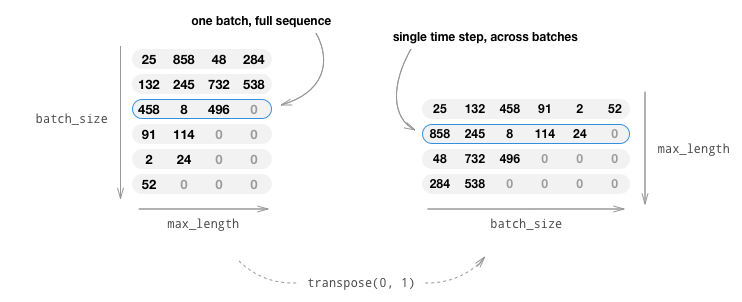

Figure from the PyTorch Chatbot Tutorial.

- Time comes first: **one column is one sentence**. `x[t]` is the word at step *t* of every sentence, which is what the decoder needs at each step.
- `zero_padding` uses `itertools.zip_longest`. It pads with 0 and does the transpose in one call.
- `binary_matrix` builds the mask. The loss uses it to ignore the padded positions.
- The batch is sorted by input length, longest first, because `pack_padded_sequence` in the encoder expects this order.


In [11]:
# 3.1 Turn sentences into padded tensors
def indexes_from_sentence(voc, sentence):
    if "UNK" in voc.word2index:      # a word outside the vocabulary becomes UNK
        sentence = replace_unknown_words(voc, sentence)
    return [voc.word2index[word] for word in sentence.split(' ')] + [EOS_token]

def zero_padding(l, fillvalue=PAD_token):
    return list(itertools.zip_longest(*l, fillvalue=fillvalue))

# Build the mask: 1 for a real word, 0 for padding, so the loss can ignore the padded positions.
def binary_matrix(l, value=PAD_token):
    return [[1 if x != value else 0 for x in seq] for seq in l]

def input_var(l, voc):
    indexes_batch = [indexes_from_sentence(voc, sentence) for sentence in l]
    lengths = torch.tensor([len(indexes) for indexes in indexes_batch])
    pad_list = zero_padding(indexes_batch)
    pad_var = torch.LongTensor(pad_list)
    return pad_var, lengths

def output_var(l, voc):
    indexes_batch = [indexes_from_sentence(voc, sentence) for sentence in l]
    max_target_len = max(len(indexes) for indexes in indexes_batch)
    pad_list = zero_padding(indexes_batch)
    mask = binary_matrix(pad_list)
    mask = torch.BoolTensor(mask)
    pad_var = torch.LongTensor(pad_list)
    return pad_var, mask, max_target_len

def batch_to_train_data(voc, pair_batch):
    # Sort the batch by the length of input sentences (descending order)
    pair_batch.sort(key=lambda x: len(x[0].split(" ")), reverse=True)
    input_batch, output_batch = [], []
    for pair in pair_batch:
        input_batch.append(pair[0])
        output_batch.append(pair[1])
    inp, lengths = input_var(input_batch, voc)
    output, mask, max_target_len = output_var(output_batch, voc)
    return inp, lengths, output, mask, max_target_len


In [12]:
# 3.2 Check on a small batch of 5 pairs
# Example for validation
small_batch_size = 5
batches = batch_to_train_data(voc, [random.choice(train_pairs) for _ in range(small_batch_size)])
input_variable, lengths, target_variable, mask, max_target_len = batches

print("input_variable:", input_variable)
print("lengths:", lengths)
print("target_variable:", target_variable)
print("mask:", mask)
print("max_target_len:", max_target_len)


input_variable: tensor([[  11, 7310,  162,   25, 7310],
        [ 121, 4992, 3121, 3572,   14],
        [ 186,   14,   11,   14,    2],
        [  22,   14,  200,   14,    0],
        [1089,   14,  187,   14,    0],
        [  14,   10,   14,    2,    0],
        [   2,    2,    2,    0,    0]])
lengths: tensor([7, 7, 7, 6, 3])
target_variable: tensor([[ 186, 2604,  111,   24,   11],
        [  22,  132,   24,   64,  251],
        [1089,  789,   39,  521,  813],
        [  14,   14,   85,    3,   92],
        [   2,    2,   10,  111,  126],
        [   0,    0,    2,   83, 3715],
        [   0,    0,    0,   10,   14],
        [   0,    0,    0,    2,    2]])
mask: tensor([[ True,  True,  True,  True,  True],
        [ True,  True,  True,  True,  True],
        [ True,  True,  True,  True,  True],
        [ True,  True,  True,  True,  True],
        [ True,  True,  True,  True,  True],
        [False, False,  True,  True,  True],
        [False, False, False,  True,  True],
        [Fa

# 4. Encoder

**The seq2seq idea.** One network, the encoder, reads the input sentence. A second network, the decoder, writes the reply one word at a time.

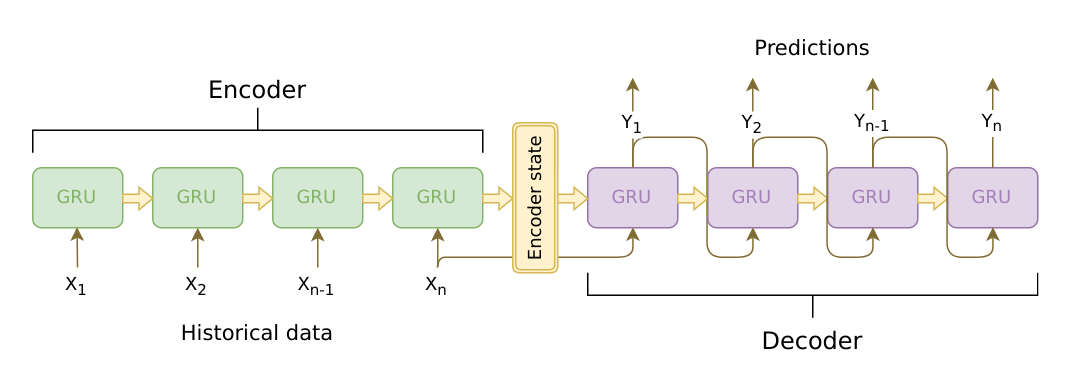

Figure: <https://jeddy92.github.io/JEddy92.github.io/ts_seq2seq_intro/>

**What the encoder does**

```
input_seq (L, B)                   word indexes
  → embedding                      (L, B, 500)     every index becomes a vector
  → pack_padded_sequence           padding is removed, so the GRU never reads it
  → bidirectional GRU, 2 layers    outputs (L, B, 1000), hidden (4, B, 500)
  → pad_packed_sequence            back to a normal tensor
  → first half + second half       outputs (L, B, 500)
```

**Bidirectional** means two GRUs read the same sentence, one from left to right and one from right to left. After each word a GRU updates its state (500 numbers), which holds what it has read so far.

```
forward  GRU →    how ──► are ──► you
                   f0      f1      f2        f1: the state after reading "how are"
backward GRU ←    how ◄── are ◄── you
                   b0      b1      b2        b1: the state after reading "you are"

output for "are" = [ f1 (500 numbers) | b1 (500 numbers) ]
```

- Every word gets both states, so it knows its left and its right context. The two halves are then added, which brings the size back to 500, the same as the decoder state.
- Bidirectional is a choice (`bidirectional=True`). The encoder can use it because the whole input sentence is known. The decoder cannot, because the later words do not exist yet.

**The two results**

| | What it is | Shape | Used by |
| --- | --- | --- | --- |
| `outputs` | the state at every word (top layer) | `(L, B, 500)` | attention: the decoder looks back at every input word |
| `hidden` | the state after the last word (every layer and direction) | `(4, B, 500)` | the decoder's first state: the meaning of the whole sentence |

The 4 parts of `hidden` are in this order: layer 0 forward, layer 0 backward, layer 1 forward, layer 1 backward.

In `nn.GRU(embedding.embedding_dim, hidden_size, ...)` the first argument is the size of a word vector and the second is the size of the state. Both are 500 here.


In [13]:
# 4.1 Encoder
class EncoderRNN(nn.Module):
    def __init__(self, hidden_size, embedding, n_layers=1, dropout=0.0):
        super().__init__()
        self.n_layers = n_layers
        self.hidden_size = hidden_size
        self.embedding = embedding

        # input_size is the word-vector size; hidden_size is the size of the GRU state
        self.gru = nn.GRU(embedding.embedding_dim, hidden_size, n_layers,
                          dropout=(0 if n_layers == 1 else dropout), bidirectional=True)

    def forward(self, input_seq, input_lengths, hidden=None):
        # Convert word indexes to embeddings
        embedded = self.embedding(input_seq)
        # Pack padded batch of sequences for RNN module
        packed = nn.utils.rnn.pack_padded_sequence(embedded, input_lengths)
        # Forward pass through GRU
        outputs, hidden = self.gru(packed, hidden)
        # Unpack padding
        outputs, _ = nn.utils.rnn.pad_packed_sequence(outputs)
        # Sum bidirectional GRU outputs
        outputs = outputs[:, :, :self.hidden_size] + outputs[:, :, self.hidden_size:]
        # Return output and final hidden state(its understanding for the whole sentence)
        return outputs, hidden


In [14]:
# 4.2 Check: run the encoder on the small batch
hidden_size = 500
embedding_dim = 500
embedding = nn.Embedding(voc.num_words, embedding_dim)
enc = EncoderRNN(hidden_size, embedding, n_layers=2, dropout=0.1)
outputs, hidden = enc(input_variable, lengths)
print("Encoder outputs shape:", outputs.shape)
print("Encoder hidden shape:", hidden.shape)


Encoder outputs shape: torch.Size([7, 5, 500])
Encoder hidden shape: torch.Size([4, 5, 500])


# 5. Attention and decoder

The decoder writes **one word per call**. Before it chooses the word, it looks back at the encoder outputs and decides how much to take from each input word. This is attention.

```
input_step (1, B)                            the previous word
  → embedding + dropout                      (1, B, 500)
  → GRU, one direction, 2 layers             rnn_output (1, B, 500), hidden (2, B, 500)
  → Attn(rnn_output, encoder_outputs)        attention weights (B, 1, L)
  → weights × encoder_outputs  (bmm)         context (B, 1, 500)
  → concatenate [rnn_output, context]        (B, 1000)
  → Linear + tanh                            (B, 500)
  → Linear + softmax                         word probabilities (B, V)
```

Without attention the decoder would only have `hidden`, one summary of the whole sentence. For long sentences that summary loses detail.


## 5.1 Attention: a worked example

The input is `where are you from`, and the decoder is about to write a word. To keep the numbers small, the vectors here have 2 numbers instead of 500 (made-up values).

```
input words:         where     are      you      from
encoder outputs:     [3, 0]    [0, 1]   [0, 2]   [2, 0]
decoder state h_t:   [1, 0]

1. score (dot)         3         0        0        2      multiply element by element, then add
2. softmax            0.68      0.03     0.03     0.25    the attention weights; they sum to 1
3. weighted sum       0.68×[3,0] + 0.03×[0,1] + 0.03×[0,2] + 0.25×[2,0] = [2.55, 0.10]    the context
4. concatenate        [h_t, context] = [1, 0, 2.55, 0.10]  → linear layers → the next word
```

- Steps 1 and 2 are the `Attn` class. Steps 3 and 4 are in the decoder.
- The weights are computed again for every output word, because the decoder state `h_t` changes after each word.

Luong et al. (2015) give three ways to compute the score. $h_t$ is the decoder state and $\bar{h}_s$ is one encoder output.

| `method` | Score | Learned parameters |
| --- | --- | --- |
| `dot` (used here) | $h_t^\top \bar{h}_s$ | none |
| `general` | $h_t^\top W_a \bar{h}_s$ | one matrix |
| `concat` | $v_a^\top \tanh(W_a [h_t ; \bar{h}_s])$ | one matrix and one vector |

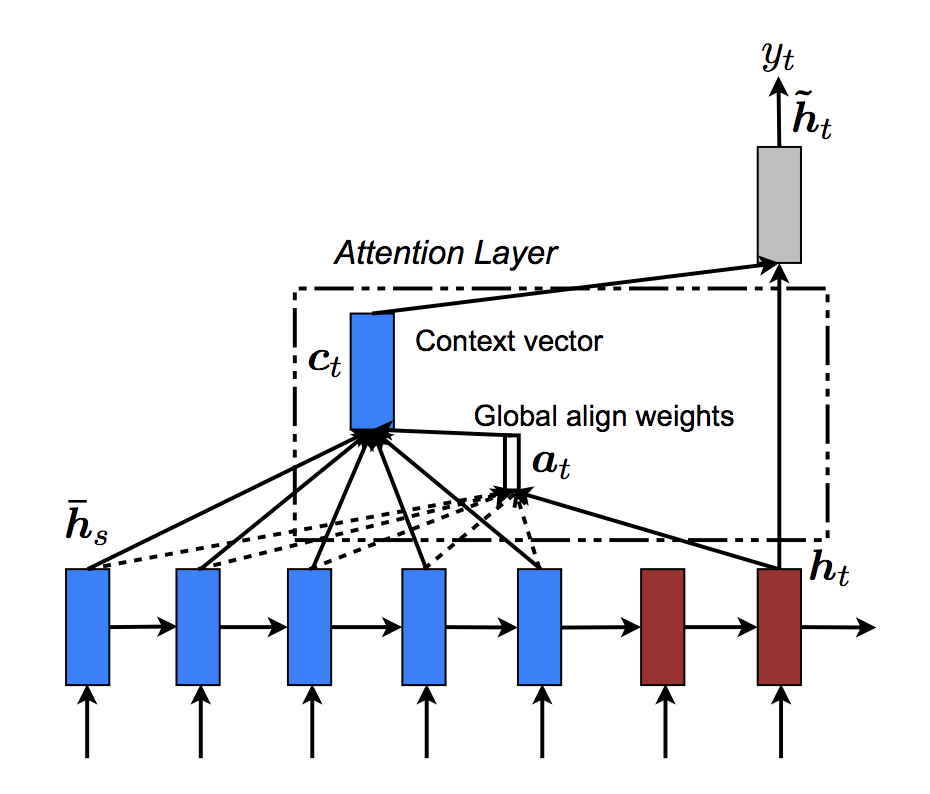

Figure from the PyTorch Chatbot Tutorial.


In [15]:
# 5.1 Luong attention layer
class Attn(nn.Module):
    def __init__(self, method, hidden_size):
        super().__init__()
        self.method = method
        self.hidden_size = hidden_size
        if self.method not in ['dot', 'general', 'concat']:
            raise ValueError(self.method, "is not an appropriate attention method.")
        if self.method == 'general':
            self.attn = nn.Linear(hidden_size, hidden_size)
        elif self.method == 'concat':
            self.attn = nn.Linear(hidden_size * 2, hidden_size)
            self.v = nn.Parameter(torch.FloatTensor(hidden_size))

    def dot_score(self, hidden, encoder_output):
        return torch.sum(hidden * encoder_output, dim=2)

    def general_score(self, hidden, encoder_output):
        energy = self.attn(encoder_output)
        return torch.sum(hidden * energy, dim=2)

    def concat_score(self, hidden, encoder_output):
        energy = self.attn(torch.cat((hidden.expand(encoder_output.size(0), -1, -1), encoder_output), 2)).tanh()
        return torch.sum(self.v * energy, dim=2)

    def forward(self, hidden, encoder_outputs):
        # Calculate the attention weights (energies) based on the given method
        if self.method == 'general':
            attn_energies = self.general_score(hidden, encoder_outputs)
        elif self.method == 'concat':
            attn_energies = self.concat_score(hidden, encoder_outputs)
        elif self.method == 'dot':
            attn_energies = self.dot_score(hidden, encoder_outputs)

        # Transpose max_length and batch_size dimensions
        attn_energies = attn_energies.t()

        # Return the softmax normalized probability scores (with added dimension)
        return F.softmax(attn_energies, dim=1).unsqueeze(1)


## 5.2 Decoder: inputs and outputs of one step

| Name | Shape | Meaning |
| --- | --- | --- |
| `input_step` | `(1, B)` | the previous word of every sentence |
| `last_hidden` | `(2, B, 500)` | the decoder state so far |
| `encoder_outputs` | `(L, B, 500)` | from the encoder |
| returns `output` | `(B, V)` | probability of each word being the next word |
| returns `hidden` | `(2, B, 500)` | the new decoder state |

- `output` is already a probability (softmax is applied), so the loss function takes `-log` itself.
- The decoder shares the `embedding` table with the encoder.
- `self.concat` is the name of a linear layer. It is not the same thing as `torch.cat`.


In [16]:
# 5.2 Decoder (one time step per call)
class LuongAttnDecoderRNN(nn.Module):
    def __init__(self, attn_model, embedding, hidden_size, output_size, n_layers=1, dropout=0.1):
        super().__init__()

        # Keep for reference
        self.attn_model = attn_model
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.n_layers = n_layers
        self.dropout = dropout

        # Define layers
        self.embedding = embedding
        self.embedding_dropout = nn.Dropout(dropout)
        self.gru = nn.GRU(embedding.embedding_dim, hidden_size, n_layers,
                          dropout=(0 if n_layers == 1 else dropout))
        self.concat = nn.Linear(hidden_size * 2, hidden_size)
        self.out = nn.Linear(hidden_size, output_size)

        self.attn = Attn(attn_model, hidden_size)

    def forward(self, input_step, last_hidden, encoder_outputs):
        # Note: we run this one step (word) at a time

        # Get embedding of current input word
        embedded = self.embedding(input_step)
        embedded = self.embedding_dropout(embedded)

        # Forward through unidirectional GRU
        rnn_output, hidden = self.gru(embedded, last_hidden)

        # Calculate attention weights from the current GRU output
        attn_weights = self.attn(rnn_output, encoder_outputs)

        # Multiply attention weights to encoder outputs to get new "weighted sum" context vector
        context = attn_weights.bmm(encoder_outputs.transpose(0, 1))

        # Concatenate weighted context vector and GRU output using Luong eq. 5
        rnn_output = rnn_output.squeeze(0)
        context = context.squeeze(1)
        concat_input = torch.cat((rnn_output, context), 1)
        concat_output = torch.tanh(self.concat(concat_input))

        # Predict next word using Luong eq. 6
        output = F.softmax(self.out(concat_output), dim=1)

        # Return output and final hidden state
        return output, hidden


In [17]:
# 5.3 Check: one decoder step
dec = LuongAttnDecoderRNN('dot', embedding, hidden_size, voc.num_words, n_layers=2, dropout=0.1)
decoder_input = torch.LongTensor([[SOS_token for _ in range(5)]])  # (1, 5)
decoder_hidden = hidden[:dec.n_layers]  # Use last (2, 5, 500)
out, h = dec(decoder_input, decoder_hidden, outputs)
print("Decoder output shape:", out.shape)
print("Decoder output sum (should be 1):", out.sum(dim=1))


Decoder output shape: torch.Size([5, 7311])
Decoder output sum (should be 1): tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<SumBackward1>)


# 6. Loss and one training step

**Goal:** make the model give a high probability to the correct next word.

One training iteration (one batch):

```
zero the gradients
encoder reads the whole batch                    → encoder_outputs, encoder_hidden
decoder input  = SOS for every sentence
decoder hidden = encoder_hidden[:decoder.n_layers]
for t in 0 .. max_target_len - 1:
    decoder writes one word                      → probabilities (B, V)
    loss += masked loss at step t
    next input = target word t                   (teacher forcing)
loss.backward() → clip the gradients → both optimizers take one step
```

At the start the loss is close to ln(7,311) = 8.90, which is the loss of a random guess.


## 6.1 Masked loss

Example for one time step, with 3 sentences and a vocabulary of 5 words:

```
inp: the model's probabilities                      target   mask
          w0     w1     w2     w3     w4
s0   [  0.10,  0.20,  0.60,  0.05,  0.05 ]             2      True
s1   [  0.70,  0.10,  0.10,  0.05,  0.05 ]             0      False   (padding)
s2   [  0.20,  0.20,  0.20,  0.30,  0.10 ]             4      True

gather: probability of the correct word       0.60     0.70     0.10
-log                                          0.51     0.36     2.30
keep where mask is True, then take the mean   (0.51 + 2.30) / 2 ≈ 1.41
```

- The lower the probability of the correct word, the larger the loss.
- Padded positions are not real words, so the mask removes them from the loss.


In [18]:
# 6.1 Masked loss
def mask_nll_loss(inp, target, mask):
    n_total = mask.sum()
    cross_entropy = -torch.log(torch.gather(inp, 1, target.view(-1, 1)).squeeze(1))
    loss = cross_entropy.masked_select(mask).mean()
    return loss.to(device), n_total.item()


## 6.2 One training iteration

**Teacher forcing.** With teacher forcing the next input is the correct word, even when the model's own guess was wrong.

```
target reply:   i   m   fine   .   EOS

training (teacher forcing)                inference
input:    SOS   i    m    fine   .        SOS   w1'  w2'  w3'  ...
output:   w1'   w2'  w3'  w4'    w5'      w1'   w2'  w3'  w4'  ...
```

Training is faster this way. But with `teacher_forcing_ratio = 1.0` the decoder never sees its own mistakes during training, and at inference it has to continue from them.

**Gradient clipping.** RNN gradients can become very large. When the gradient norm is above `clip`, it is scaled down, so one bad batch cannot throw the weights far away.

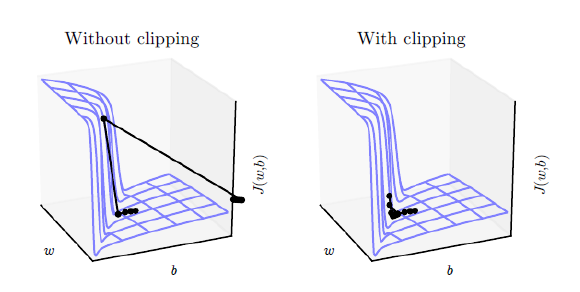

Figure: Goodfellow et al., *Deep Learning*, 2016. <https://www.deeplearningbook.org/>

**The decoder's first state.** `encoder_hidden[:decoder.n_layers]` takes the first two parts of `hidden`. These are the forward and backward states of encoder layer 0.


In [19]:
# 6.2 One training iteration (one batch)
def train(input_variable, lengths, target_variable, mask, max_target_len,
          encoder, decoder, embedding, encoder_optimizer, decoder_optimizer,
          batch_size, clip, max_length=MAX_LENGTH):
    # Zero gradients
    encoder_optimizer.zero_grad()
    decoder_optimizer.zero_grad()

    # Move to device
    input_variable = input_variable.to(device)
    target_variable = target_variable.to(device)
    mask = mask.to(device)

    # Initialize variables
    loss = 0
    print_losses = []
    n_totals = 0

    # Forward pass through encoder
    encoder_outputs, encoder_hidden = encoder(input_variable, lengths)

    # Prepare decoder input and hidden state
    decoder_input = torch.LongTensor([[SOS_token for _ in range(batch_size)]]).to(device)
    decoder_hidden = encoder_hidden[:decoder.n_layers]

    # Determine if we are using teacher forcing this iteration
    use_teacher_forcing = True if random.random() < teacher_forcing_ratio else False

    # Forward batch of sequences through decoder one time step at a time
    for t in range(max_target_len):
        decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden, encoder_outputs)

        # Teacher forcing: next input is current target
        if use_teacher_forcing:
            decoder_input = target_variable[t].view(1, -1)
        else:
            # No teacher forcing: next input is decoder's own current output
            _, topi = decoder_output.topk(1)
            decoder_input = topi.transpose(0, 1).detach()  # detach from history as input

        # Calculate and accumulate loss
        mask_loss, n_total = mask_nll_loss(decoder_output, target_variable[t], mask[t])
        loss += mask_loss
        print_losses.append(mask_loss.item() * n_total)
        n_totals += n_total

    # Backward pass
    loss.backward()

    # Clip gradients: gradients are modified in place
    nn.utils.clip_grad_norm_(encoder.parameters(), clip)
    nn.utils.clip_grad_norm_(decoder.parameters(), clip)

    # Adjust model weights
    encoder_optimizer.step()
    decoder_optimizer.step()

    return sum(print_losses) / n_totals


# 7. Inference

At inference there is no correct answer to feed in. The decoder's own output becomes its next input. This is the only difference from training.

```
training:    SOS → decoder → w1'      next input = the correct word w1
inference:   SOS → decoder → w1'      next input = w1'
```


## 7.1 Greedy search

At every step, take the word with the highest probability and use it as the next input (made-up numbers):

```
step 1:   i 0.41    you 0.22    what 0.08   ...    →  "i"
step 2:   m 0.35    don 0.30    am 0.05     ...    →  "m"
step 3:   fine 0.28 not 0.21    sorry 0.10  ...    →  "fine"
```

- It is simple and fast, but it always takes the safest word, so replies tend to be short and generic. Section 7.3 adds two other searches.
- The loop always runs `max_length` (10) steps. It does not stop when `EOS` is written.
- When the vocabulary has `UNK`, its probability is set to 0 before the best word is taken, so the bot never writes `UNK`.


In [20]:
# 7.1 Greedy search decoder
class GreedySearchDecoder(nn.Module):
    def __init__(self, encoder, decoder, unk_index=None):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.unk_index = unk_index      # index of UNK in the vocabulary; None when the vocabulary has no UNK

    def forward(self, input_seq, input_length, max_length):
        # Forward input through encoder model
        encoder_outputs, encoder_hidden = self.encoder(input_seq, input_length)

        # Prepare decoder's initial input and hidden state
        decoder_hidden = encoder_hidden[:self.decoder.n_layers]
        decoder_input = torch.ones(1, 1, device=device, dtype=torch.long) * SOS_token

        # Initialize tensors to append decoded words to
        all_tokens = torch.zeros([0], device=device, dtype=torch.long)
        all_scores = torch.zeros([0], device=device)

        # Iteratively decode one word token at a time
        for _ in range(max_length):
            decoder_output, decoder_hidden = self.decoder(decoder_input, decoder_hidden, encoder_outputs)
            if self.unk_index is not None:
                decoder_output[:, self.unk_index] = 0      # the bot must not say UNK
            # Obtain most likely word token and its softmax score
            decoder_scores, decoder_input = torch.max(decoder_output, dim=1)
            # Record token and score
            all_tokens = torch.cat((all_tokens, decoder_input), dim=0)
            all_scores = torch.cat((all_scores, decoder_scores), dim=0)
            # Prepare current token to be next decoder input (add a dimension)
            decoder_input = torch.unsqueeze(decoder_input, 0)

        # Return collections of word tokens and scores
        return all_tokens, all_scores


## 7.2 Chat functions

`evaluate` turns one sentence into a reply:

```
"how are you ?"                          a cleaned sentence
   │ indexes_from_sentence
   ▼
[[7, 12, 3, 6, 2]]                       word indexes, as a batch of one sentence
   │ torch.LongTensor(...).transpose(0, 1)
   ▼
input_batch (L, 1), lengths = [5]        one column is one sentence
   │ searcher(input_batch, lengths, max_length)
   ▼
tokens                                   the index of every word of the reply
   │ voc.index2word
   ▼
["i", "m", "fine", ".", "EOS", ...]      the reply as words; the decoder always writes max_length words
   │ keep the words before the first EOS
   ▼
["i", "m", "fine", "."]                  the reply
```

(The indexes and the reply are an illustration.)

The words after the first `EOS` are dropped. The loss masks every position after `EOS` (6.1), so the model never learned what to write there, and those words are noise such as `hello . . . . .`.

`evaluate_input` is the chat loop: read a line, stop on `q` or `quit`, clean it with `normalize_string` (the same cleaning as the training data), call `evaluate`, remove `EOS` and `PAD`, print the reply.

An input word that is not in the vocabulary becomes `UNK` (3.1), so every sentence gets a reply. With a vocabulary that has no `UNK` (`USE_UNK = False`, or an older checkpoint) the lookup raises `KeyError`: the loop prints `Error: Encountered unknown word.` and the bot gives no reply to that sentence.


In [21]:
# 7.2 Chat functions
def evaluate(encoder, decoder, searcher, voc, sentence, max_length=MAX_LENGTH):
    # Format input sentence as a batch
    indexes_batch = [indexes_from_sentence(voc, sentence)]
    lengths = torch.tensor([len(indexes) for indexes in indexes_batch])
    input_batch = torch.LongTensor(indexes_batch).transpose(0, 1).to(device)

    # Decode sentence with searcher
    tokens, scores = searcher(input_batch, lengths.to("cpu"), max_length)
    words = [voc.index2word[token.item()] for token in tokens]
    if 'EOS' in words:
        words = words[:words.index('EOS')]
    return words

def evaluate_input(encoder, decoder, searcher, voc):
    input_sentence = ''
    while True:
        try:
            # Get input sentence
            input_sentence = input('> ')
            if input_sentence.lower() in ['q', 'quit']:
                break
            # Normalize sentence
            input_sentence = normalize_string(input_sentence)
            # Evaluate sentence
            output_words = evaluate(encoder, decoder, searcher, voc, input_sentence)
            # Format and print response sentence
            output_words[:] = [x for x in output_words if not (x == 'EOS' or x == 'PAD')]
            print('Bot:', ' '.join(output_words))

        except KeyError:
            print("Error: Encountered unknown word.")


## 7.3 Sampling and beam search

Greedy search takes the single best word at every step. Two other ways to write the reply:

```
greedy     always the most likely word                         →  the safest reply
sampling   draw the next word at random from the top_k words   →  varied replies, more mistakes
beam       keep the beam_width best unfinished replies         →  the reply with the best total score
```

Beam search with width 2 (made-up numbers):

```
step 1:   "i" 0.41      "you" 0.22                             keep both
step 2:   "i m" 0.14    "i don" 0.12    "you re" 0.11   ...    keep the best 2 of all continuations
...       a reply that writes EOS is finished; at the end, the finished reply with the best score wins
```

- The score of a reply is the mean log-probability of its words, so a short reply does not win only because it is short.
- Plain beam search finds replies that are even more likely, and the most likely replies are the generic ones. So the score also subtracts `PRIOR_WEIGHT` × the log-frequency of each word in the training replies. A reply made of very common words, such as `i don t know .`, loses score. This follows the idea of Li et al. (2016), *A Diversity-Promoting Objective Function for Neural Conversation Models*.
- `make_searcher` builds the search named by `SEARCH_METHOD`. It is used for chatting and for validation.

Measured on the 200 validation sentences, with the same trained model for every row (the standard error of each overall score is about 0.05):

| Search | overall | relevance | fluency | specificity | different replies |
| --- | --- | --- | --- | --- | --- |
| greedy | 2.71 | 2.56 | 3.72 | 1.84 | 77 |
| sampling, top 5, temperature 0.7 | 2.61 | 2.42 | 3.52 | 1.89 | 123 |
| sampling, top 10, temperature 1.0 | 2.47 | 2.21 | 3.29 | 1.92 | 164 |
| beam 10 | 2.78 | 2.69 | 3.77 | 1.87 | 52 |
| **beam 10, `PRIOR_WEIGHT` 0.3** | **2.84** | 2.54 | 3.91 | 2.06 | 70 |
| beam 10, `PRIOR_WEIGHT` 0.5 | 2.79 | 2.40 | 3.87 | 2.10 | 86 |

Sampling gives many different replies but lower scores. Plain beam search is the most generic: `i don t know .` is 46 of its 200 replies. The penalty for common words gives the best overall score, so it is the default.

In [22]:
# 7.3 Two more search decoders: sampling and beam search
class SamplingSearchDecoder(nn.Module):
    def __init__(self, encoder, decoder, unk_index=None, top_k=10, temperature=1.0):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.unk_index = unk_index
        self.top_k = top_k                  # draw from the top_k most likely words only
        self.temperature = temperature      # below 1: closer to greedy; above 1: more random

    def forward(self, input_seq, input_length, max_length):
        encoder_outputs, encoder_hidden = self.encoder(input_seq, input_length)
        decoder_hidden = encoder_hidden[:self.decoder.n_layers]
        decoder_input = torch.ones(1, 1, device=device, dtype=torch.long) * SOS_token
        all_tokens = torch.zeros([0], device=device, dtype=torch.long)
        all_scores = torch.zeros([0], device=device)

        for _ in range(max_length):
            decoder_output, decoder_hidden = self.decoder(decoder_input, decoder_hidden, encoder_outputs)
            if self.unk_index is not None:
                decoder_output[:, self.unk_index] = 0      # the bot must not say UNK
            # Keep the top_k words and draw one of them at random, in proportion to its probability
            top_probs, top_indexes = torch.topk(decoder_output ** (1 / self.temperature), self.top_k, dim=1)
            choice = torch.multinomial(top_probs, 1)
            decoder_input = top_indexes.gather(1, choice)
            all_tokens = torch.cat((all_tokens, decoder_input[0]), dim=0)
            all_scores = torch.cat((all_scores, top_probs.gather(1, choice)[0]), dim=0)

        return all_tokens, all_scores


class BeamSearchDecoder(nn.Module):
    def __init__(self, encoder, decoder, unk_index=None, beam_width=5, word_log_prior=None, prior_weight=0.0):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.unk_index = unk_index
        self.beam_width = beam_width            # how many unfinished replies are kept at every step
        self.word_log_prior = word_log_prior    # (V,) log of how often each word appears in the training replies
        self.prior_weight = prior_weight        # 0: plain beam search; above 0: replies made of common words lose score

    def reply_score(self, tokens, log_prob):
        # Mean log-probability per word, so that short replies do not win only because they are short.
        # With prior_weight > 0 the log-frequency of each word is subtracted: a reply made of very
        # common words, such as "i don t know .", gets a lower score.
        words = tokens[1:]                      # without SOS
        if self.prior_weight > 0:
            log_prob = log_prob - self.prior_weight * sum(self.word_log_prior[token].item() for token in words)
        return log_prob / len(words)

    def forward(self, input_seq, input_length, max_length):
        encoder_outputs, encoder_hidden = self.encoder(input_seq, input_length)
        decoder_hidden = encoder_hidden[:self.decoder.n_layers]

        # A beam is (tokens so far, sum of the log-probabilities of its words, decoder state)
        beams = [([SOS_token], 0.0, decoder_hidden)]
        finished = []
        for _ in range(max_length):
            candidates = []
            for tokens, log_prob, hidden in beams:
                decoder_input = torch.tensor([[tokens[-1]]], device=device)
                decoder_output, new_hidden = self.decoder(decoder_input, hidden, encoder_outputs)
                if self.unk_index is not None:
                    decoder_output[:, self.unk_index] = 0      # the bot must not say UNK
                top_probs, top_indexes = torch.topk(decoder_output[0], self.beam_width)
                for prob, index in zip(top_probs.tolist(), top_indexes.tolist()):
                    if prob > 0:
                        candidates.append((tokens + [index], log_prob + math.log(prob), new_hidden))
            # Keep the beam_width best candidates; a candidate that ends with EOS is a finished reply
            candidates.sort(key=lambda candidate: candidate[1], reverse=True)
            beams = []
            for candidate in candidates[:self.beam_width]:
                (finished if candidate[0][-1] == EOS_token else beams).append(candidate)
            if not beams:
                break

        # Take the reply with the best score
        tokens, log_prob, _ = max(finished + beams, key=lambda candidate: self.reply_score(candidate[0], candidate[1]))
        return torch.tensor(tokens[1:], device=device, dtype=torch.long), self.reply_score(tokens, log_prob)


def build_word_log_prior(voc, pairs):
    # log of the share of each word among all words of the training replies (EOS counts as a word)
    counts = torch.ones(voc.num_words)      # start at 1, so that no word has a count of 0
    for pair in pairs:
        counts[EOS_token] += 1
        for word in pair[1].split(' '):
            if word in voc.word2index:
                counts[voc.word2index[word]] += 1
    return torch.log(counts / counts.sum())


# The search used for chatting and for validation
SEARCH_METHOD = 'beam'      # 'greedy', 'sampling' or 'beam'
BEAM_WIDTH = 10
PRIOR_WEIGHT = 0.3          # 0 gives plain beam search

def make_searcher(encoder, decoder, voc):
    unk_index = voc.word2index.get("UNK")
    if SEARCH_METHOD == 'greedy':
        return GreedySearchDecoder(encoder, decoder, unk_index)
    if SEARCH_METHOD == 'sampling':
        return SamplingSearchDecoder(encoder, decoder, unk_index, top_k=5, temperature=0.7)
    word_log_prior = build_word_log_prior(voc, train_pairs)
    return BeamSearchDecoder(encoder, decoder, unk_index, BEAM_WIDTH, word_log_prior, PRIOR_WEIGHT)

# 8. Validation with an LLM judge

One sentence has many good replies, so a good reply does not have to match the reply in the corpus. The replies are therefore not compared with the corpus. A language model, the judge, reads each input and reply and gives three scores from 1 to 5.

```
held-out sentences  (from movies that are never used in training)
   │  generate_replies: the chatbot answers every sentence
   ▼
(input, reply) pairs
   │  judge_replies: the judge scores every pair
   ▼
mean relevance, fluency, specificity and overall score, and the share of answered inputs
```

| Score | Question | A reply with a low score |
| --- | --- | --- |
| relevance | Does the reply respond to the input? | `where are you from ?` → `i m a car .` |
| fluency | Is it one natural, complete sentence? | `i m fine . me . .` |
| specificity | Is it specific to this input, not a line that fits any input? | `i don t know .` |

- **Held-out sets.** 200 validation sentences and 200 test sentences are drawn, with a fixed seed, from the validation and test pairs prepared in 2.2. They are cleaned in the same way as the training pairs.
- **During training** the same 50 validation sentences are scored at every validation, so the scores of different iterations can be compared.
- **No reply.** An empty reply, or no reply at all (without `UNK`, an input with a word outside the vocabulary gets no reply), counts as the lowest score (1) on all three criteria.
- **The judge is blind.** It sees one input and one reply. It does not know which model or setting wrote the reply. The temperature is 0 and the judge's thinking mode is off.
- **The API key** is read from a local `.env` file. It is not stored in the notebook.


In [23]:
# 8.1 Input sentences for validation and the final test
N_EVAL = 200       # sentences in each set
N_QUICK = 50       # validation sentences scored during training

# A fixed seed gives the same sentences in every run
val_inputs = [pair[0] for pair in random.Random(0).sample(val_pairs, N_EVAL)]
test_inputs = [pair[0] for pair in random.Random(0).sample(test_pairs, N_EVAL)]
quick_inputs = val_inputs[:N_QUICK]      # a fixed subset: the same 50 sentences at every validation
print(len(val_inputs), len(test_inputs), len(quick_inputs))
for sentence in quick_inputs[:5]:
    print(sentence)


200 200 50
yes . we can pray .
no .
how much did ya lose ?
tell me you ll call .
where are you staying ?


In [24]:
# 8.2 Let the chatbot reply to a list of sentences
def generate_replies(inputs, encoder, decoder, voc):
    searcher = make_searcher(encoder, decoder, voc)
    replies = []
    with torch.no_grad():
        for sentence in inputs:
            try:
                words = evaluate(encoder, decoder, searcher, voc, sentence)
                replies.append(' '.join(word for word in words if word not in ('EOS', 'PAD')))
            except KeyError:
                replies.append(None)       # unknown word and no UNK in the vocabulary: no reply
    return replies


In [25]:
# 8.3 The LLM judge
JUDGE_MODEL = "deepseek-flash"
CRITERIA = ["relevance", "fluency", "specificity"]

JUDGE_PROMPT = """You grade one reply of a movie-dialogue chatbot.
The input and the reply are lower-cased and their punctuation is separated by spaces. Do not lower the score for that.

Give three scores from 1 (very bad) to 5 (very good):
- relevance: does the reply respond to the input sentence?
- fluency: is the reply one natural, complete sentence, with no broken or left-over words?
- specificity: is the reply specific to this input, and not a generic line that fits any input (such as "i don t know .")?

Answer with JSON only, for example: {"relevance": 3, "fluency": 4, "specificity": 2}"""

# The API key is read from the local file .env, which holds one line: DEEPSEEK_API_KEY=...
with open(".env") as f:
    env = dict(line.strip().split("=", 1) for line in f if "=" in line)
judge_client = OpenAI(api_key=env["DEEPSEEK_API_KEY"], base_url="https://api.deepseek.com")

def judge_one(sentence, reply):
    # Ask the judge for the three scores; ask again when the answer is not valid JSON
    for _ in range(3):
        response = judge_client.chat.completions.create(
            model=JUDGE_MODEL, temperature=0, max_tokens=100,
            response_format={"type": "json_object"},
            extra_body={"thinking": {"type": "disabled"}},      # no thinking mode: faster
            messages=[{"role": "system", "content": JUDGE_PROMPT},
                      {"role": "user", "content": f"Input: {sentence}\nReply: {reply}"}])
        try:
            answer = json.loads(response.choices[0].message.content)
            scores = {name: int(answer[name]) for name in CRITERIA}
            if all(1 <= value <= 5 for value in scores.values()):
                return scores
        except (ValueError, KeyError, TypeError):
            pass
    raise RuntimeError(f"The judge gave no valid scores for {sentence!r} -> {reply!r}")

def judge_replies(inputs, replies):
    # Mean scores of the replies. A missing or empty reply gets the lowest score without asking the judge.
    lowest = {name: 1 for name in CRITERIA}
    with ThreadPoolExecutor(max_workers=8) as pool:
        rows = list(pool.map(lambda pair: judge_one(*pair) if pair[1] else lowest, zip(inputs, replies)))
    means = {name: sum(row[name] for row in rows) / len(rows) for name in CRITERIA}
    means["overall"] = sum(means[name] for name in CRITERIA) / len(CRITERIA)
    means["answered"] = sum(bool(reply) for reply in replies) / len(replies)
    return means

def format_scores(scores):
    # For example: relevance 2.10, fluency 3.00, specificity 1.80, overall 2.30, answered 79%
    return ", ".join(f"{name} {scores[name]:.2f}" for name in CRITERIA + ["overall"]) + f", answered {scores['answered']:.0%}"


In [26]:
# 8.4 Validation: the chatbot answers the sentences, the judge scores the replies
def validate(inputs, encoder, decoder, voc):
    was_training = encoder.training
    encoder.eval()
    decoder.eval()
    replies = generate_replies(inputs, encoder, decoder, voc)
    if was_training:
        encoder.train()
        decoder.train()
    return judge_replies(inputs, replies)


# 9. Training loop with validation

```
for iteration in 1 .. n_iteration:
    train on one random batch of 64 pairs
    every print_every iterations:      record and print the mean training loss
    every validate_every iterations:   the chatbot answers the 50 validation sentences
                                       the judge scores the replies
    every save_every iterations:       save a checkpoint
```

- Every iteration uses 64 pairs drawn at random. It does not walk through the data epoch by epoch. 4,000 iterations see about 256,000 pairs, which is about 4.4 passes over the 58,118 pairs.
- A checkpoint holds the weights of the encoder, decoder and embedding, the state of both optimizers, the loss, the iteration number, the vocabulary and the history of losses and scores. It can be used to chat or to continue training.
- Validation runs more often than saving, because most of the gain comes in the first 1,000 iterations and a checkpoint is a large file. If a validation fails, for example because the judge cannot be reached, a checkpoint is saved at that iteration, training stops and prints the checkpoint file. Set `load_filename` to that file and run the cells again: the run validates that checkpoint first and then continues.
- `plot_history` draws two charts and saves them as one image file, `history.png`, in the folder of the run's checkpoints. The training loss shows how well the model fits the training pairs. The judge scores show whether the replies to unseen sentences get better.


In [27]:
# 9.1 Training loop with validation
def save_checkpoint(path, iteration, loss, history, voc, encoder, decoder,
                    encoder_optimizer, decoder_optimizer, embedding):
    torch.save({
        'iteration': iteration,
        'en': encoder.state_dict(),
        'de': decoder.state_dict(),
        'en_opt': encoder_optimizer.state_dict(),
        'de_opt': decoder_optimizer.state_dict(),
        'loss': loss,
        'voc_dict': voc.__dict__,
        'embedding': embedding.state_dict(),
        'history': history,
    }, path)

def train_iters(model_name, voc, pairs, encoder, decoder, encoder_optimizer,
                decoder_optimizer, embedding, encoder_n_layers, decoder_n_layers,
                save_dir, n_iteration, batch_size, print_every, validate_every, save_every,
                clip, corpus_name, load_filename, val_inputs):
    # Load batches for each iteration
    training_batches = [batch_to_train_data(voc, [random.choice(pairs) for _ in range(batch_size)])
                        for _ in range(n_iteration)]

    # history['loss']: (iteration, mean training loss); history['val']: (iteration, judge scores)
    start_iteration = 1
    history = {'loss': [], 'val': []}
    checkpoint = None
    if load_filename:
        checkpoint = torch.load(load_filename, map_location=device)
        start_iteration = checkpoint['iteration'] + 1
        history = checkpoint.get('history', history)

    directory = os.path.join(save_dir, model_name, corpus_name,
                             f"{encoder_n_layers}-{decoder_n_layers}_{hidden_size}")
    os.makedirs(directory, exist_ok=True)

    def checkpoint_and_validate(iteration, loss):
        path = os.path.join(directory, f"{iteration}_checkpoint.tar")
        saved = (voc, encoder, decoder, encoder_optimizer, decoder_optimizer, embedding)
        try:
            scores = validate(val_inputs, encoder, decoder, voc)
        except Exception as error:
            save_checkpoint(path, iteration, loss, history, *saved)      # a failed validation loses no training
            print(f"Validation failed at iteration {iteration}: {error}")
            print(f"Training stopped. To continue, set load_filename = {path!r} and run the cells again.")
            raise
        history['val'].append((iteration, scores))
        if iteration % save_every == 0:
            save_checkpoint(path, iteration, loss, history, *saved)
        print(f"Iteration: {iteration}; Validation: {format_scores(scores)}")

    # A checkpoint that was saved just before a failed validation is validated first
    if checkpoint and 'history' in checkpoint and checkpoint['iteration'] % validate_every == 0 \
            and checkpoint['iteration'] not in [iteration for iteration, _ in history['val']]:
        checkpoint_and_validate(checkpoint['iteration'], checkpoint['loss'])

    print("Training...")
    print_loss = 0
    for iteration in range(start_iteration, n_iteration + 1):
        training_batch = training_batches[iteration - 1]
        input_variable, lengths, target_variable, mask, max_target_len = training_batch

        # Run a training iteration with batch
        loss = train(input_variable, lengths, target_variable, mask, max_target_len,
                     encoder, decoder, embedding, encoder_optimizer, decoder_optimizer,
                     batch_size, clip)
        print_loss += loss

        if iteration % print_every == 0:
            mean_loss = print_loss / print_every
            print_loss = 0
            history['loss'].append((iteration, mean_loss))
            print(f"Iteration: {iteration}; Percent complete: {iteration / n_iteration * 100:.1f}%; Average loss: {mean_loss:.4f}")

        if iteration % validate_every == 0:
            checkpoint_and_validate(iteration, loss)

    return history


In [28]:
# 9.2 Chart of a training run: the training loss, and the judge scores on the validation sentences.
# The chart is shown and saved as an image file.
def plot_history(history, filename):
    ink, muted, grid, surface = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
    colors = {"relevance": "#2a78d6", "fluency": "#eb6834", "specificity": "#1baf7a", "overall": ink}

    fig, (ax_loss, ax_val) = plt.subplots(1, 2, figsize=(11, 3.8), facecolor=surface)
    for ax in (ax_loss, ax_val):
        ax.set_facecolor(surface)
        ax.grid(axis="y", color=grid, linewidth=1)
        ax.set_axisbelow(True)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(grid)
        ax.tick_params(colors=muted, length=0)
        ax.set_xlabel("Iteration", color=muted)

    ax_loss.set_title("Training loss", loc="left", color=ink)
    if history["loss"]:
        iterations, losses = zip(*history["loss"])
        ax_loss.plot(iterations, losses, color=colors["relevance"], linewidth=2)

    ax_val.set_title("Judge scores on the validation sentences (1 to 5)", loc="left", color=ink)
    ax_val.set_ylim(1, 5)
    ax_val.set_yticks([1, 2, 3, 4, 5])
    if history["val"]:
        iterations = [iteration for iteration, _ in history["val"]]
        for name, color in colors.items():
            values = [scores[name] for _, scores in history["val"]]
            ax_val.plot(iterations, values, color=color, linewidth=2, marker="o", markersize=5,
                        markeredgecolor=surface, markeredgewidth=2, label=name)
        # Label the end of the overall line with its value
        ax_val.annotate(f"{values[-1]:.2f}", (iterations[-1], values[-1]), xytext=(8, 0),
                        textcoords="offset points", va="center", color=ink)
        ax_val.margins(x=0.12)
        ax_val.legend(frameon=False, labelcolor=muted, ncol=4, loc="upper left", handlelength=1.5)

    plt.tight_layout()
    fig.savefig(filename, dpi=150)      # keep the chart as an image file
    plt.show()


# 10. Run

Sections 4 to 9 only define classes and functions. This section builds the model, trains it, chats with it and tests it.

```
10.1 build      embedding, encoder, decoder   (random weights, or weights from a checkpoint)
10.2 train      train_iters → train → encoder, decoder, mask_nll_loss;  every 200 iterations → validate
10.3 chat       evaluate_input → normalize_string → evaluate → the search chosen in 7.3 → encoder, decoder
10.4 validate   scores on all 200 validation sentences: the numbers used to compare settings
10.5 test       scores on the 200 test sentences: run once, at the end
```


## 10.1 Configuration and model

| Name | Value | Meaning |
| --- | --- | --- |
| `attn_model` | `'dot'` | attention score function (`'general'` and `'concat'` are the other two) |
| `hidden_size` | 500 | size of the GRU state |
| `embedding_dim` | 500 | size of a word vector |
| `encoder_n_layers`, `decoder_n_layers` | 2, 2 | number of GRU layers |
| `dropout` | 0.1 | dropout rate |
| `batch_size` | 64 | pairs per training batch |
| `load_filename` | `None` or a path | `None` starts from random weights; a path loads a checkpoint |
| `SEED` | 0 | random seed for the weights and the training batches |

The tutorial's checkpoints (`../chat_bot/data/save/cb_model/movie-corpus/2-2_500/`) can still be loaded to chat: the layer names (`embedding`, `gru`, `concat`, `out`, `attn`) and the `Voc` attribute names are the same as in the tutorial, and `embedding_dim` is 500. They were trained on all pairs, including the held-out movies, so their validation and test scores would not be valid.


In [29]:
# 10.1 Configuration and model
model_name = 'cb_unk'
attn_model = 'dot'           # the other choices are 'general' and 'concat'
hidden_size = 500
embedding_dim = 500          # word-vector size; must be 500 to load the old checkpoints
encoder_n_layers = 2
decoder_n_layers = 2
dropout = 0.1
batch_size = 64
# load_filename = None          # None trains from scratch; a checkpoint path continues from that checkpoint

load_filename = "data/save/cb_unk/movie-corpus/2-2_500/4000_checkpoint.tar"

# Fixed random seed, so that a run can be repeated
SEED = 0
random.seed(SEED)
torch.manual_seed(SEED)

# Load a checkpoint if load_filename is given
if load_filename:
    # map_location puts the saved tensors on the device we use now
    checkpoint = torch.load(load_filename, map_location=device)
    encoder_sd = checkpoint['en']
    decoder_sd = checkpoint['de']
    encoder_optimizer_sd = checkpoint['en_opt']
    decoder_optimizer_sd = checkpoint['de_opt']
    embedding_sd = checkpoint['embedding']
    # Use the vocabulary that the checkpoint was trained with
    voc.__dict__ = checkpoint['voc_dict']

print('Building encoder and decoder ...')
# Word embeddings, shared by the encoder and the decoder
embedding = nn.Embedding(voc.num_words, embedding_dim)
if load_filename:
    embedding.load_state_dict(embedding_sd)

# Build the two models from the classes defined above
encoder = EncoderRNN(hidden_size, embedding, encoder_n_layers, dropout)
decoder = LuongAttnDecoderRNN(attn_model, embedding, hidden_size, voc.num_words, decoder_n_layers, dropout)
if load_filename:
    encoder.load_state_dict(encoder_sd)
    decoder.load_state_dict(decoder_sd)

# Move the models to the selected device
encoder = encoder.to(device)
decoder = decoder.to(device)
print('Models built and ready to go!')


Building encoder and decoder ...
Models built and ready to go!


## 10.2 Training

| Name | Value | Meaning |
| --- | --- | --- |
| `clip` | 50.0 | largest gradient norm allowed |
| `teacher_forcing_ratio` | 1.0 | how often the correct word is used as the next input |
| `learning_rate` | 0.0001 | learning rate of the encoder |
| `decoder_learning_ratio` | 5.0 | the decoder learns 5 times faster |
| `n_iteration` | 4,000 | number of batches, as in the tutorial |
| `print_every` | 100 | how often the mean training loss is recorded and printed |
| `validate_every` | 200 | how often the judge scores the replies to the 50 validation sentences |
| `save_every` | 1,000 | how often a checkpoint is saved |

After training, the cell draws the chart, saves it as `history.png` in the folder of this run's checkpoints (`data/save/<model_name>/movie-corpus/2-2_500/`) and prints the iteration with the best overall validation score.


Building optimizers ...
Starting Training!
Training...


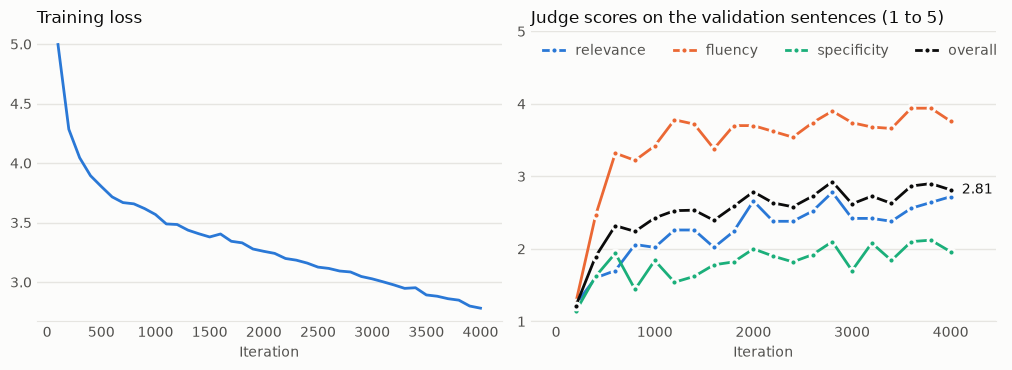

Best validation score: 2.93 at iteration 2800


In [30]:
# 10.2 Training
clip = 50.0
teacher_forcing_ratio = 1.0
learning_rate = 0.0001
decoder_learning_ratio = 5.0
n_iteration = 4000
print_every = 100
validate_every = 200         # the judge scores the 50 validation sentences every 200 iterations
save_every = 1000            # save a checkpoint every 1,000 iterations

# Put the dropout layers in training mode
encoder.train()
decoder.train()

# One optimizer for each model; the decoder learns 5 times faster
print('Building optimizers ...')
encoder_optimizer = optim.Adam(encoder.parameters(), lr=learning_rate)
decoder_optimizer = optim.Adam(decoder.parameters(), lr=learning_rate * decoder_learning_ratio)
if load_filename:
    encoder_optimizer.load_state_dict(encoder_optimizer_sd)
    decoder_optimizer.load_state_dict(decoder_optimizer_sd)

# Train and validate on the 50 quick validation sentences, then draw and save the chart
print("Starting Training!")
history = train_iters(model_name, voc, train_pairs, encoder, decoder, encoder_optimizer, decoder_optimizer,
                      embedding, encoder_n_layers, decoder_n_layers, save_dir, n_iteration, batch_size,
                      print_every, validate_every, save_every, clip, corpus_name, load_filename, quick_inputs)
# The chart goes into the folder of this run's checkpoints
run_dir = os.path.join(save_dir, model_name, corpus_name, f"{encoder_n_layers}-{decoder_n_layers}_{hidden_size}")
plot_history(history, os.path.join(run_dir, "history.png"))
if history['val']:
    best_iteration, best_scores = max(history['val'], key=lambda item: item[1]['overall'])
    print(f"Best validation score: {best_scores['overall']:.2f} at iteration {best_iteration}")


## 10.3 Chat

The cell first prints the replies to four fixed test sentences, then opens the chat. Type `q` to stop.

Replies of the tutorial's 4,000-iteration checkpoint:

```
> hello ?                  Bot: hello . me . me . ?
> where are you from ?     Bot: i m in my bedroom . me .
> how are you doing ?      Bot: i m fine . me . .
> what is your name ?      Bot: my name . my name . me .
```

The first sentence of each reply is fine. The words after it were written after `EOS` (see the limitations below).


In [31]:
# 10.3 Chat
# Put the dropout layers in evaluation mode
encoder.eval()
decoder.eval()

# The search module that writes the reply (chosen in 7.3)
searcher = make_searcher(encoder, decoder, voc)

# Fixed test sentences: keep these replies to compare with later experiments
test_sentences = ["hello ?", "where are you from ?", "how are you doing ?", "what is your name ?"]
for sentence in test_sentences:
    try:
        output_words = evaluate(encoder, decoder, searcher, voc, normalize_string(sentence))
        output_words = [x for x in output_words if not (x == 'EOS' or x == 'PAD')]
        print(f"> {sentence}\nBot: {' '.join(output_words)}")
    except KeyError:
        print(f"> {sentence}\nError: Encountered unknown word.")

# Chat with the bot (type q or quit to stop)
evaluate_input(encoder, decoder, searcher, voc)


> hello ?
Bot: i don t know .
> where are you from ?
Bot: san francisco .
> how are you doing ?
Bot: i m fine .
> what is your name ?
Bot: ahm . . . bernie .
Bot: get out of here !
Bot: hi .
Bot: hi .
Bot: how d you know this is horrible ?


## 10.4 and 10.5 Validation and test scores

- **10.4** scores the model on all 200 validation sentences. Use these numbers to compare settings.
- **10.5** scores the model on the 200 test sentences. Run it only once, after the setting is chosen, by setting `RUN_FINAL_TEST = True`. If the test set is used to choose a setting, its score is no longer an honest estimate.
- To score an earlier checkpoint, for example the one with the best validation score, set `load_filename` to it in 10.1, run 10.1 again, and then run these cells.

**Validation scores, one change at a time** (200 validation sentences; the standard error of an overall score is about 0.05):

| Setting | overall | relevance | fluency | specificity | answered |
| --- | --- | --- | --- | --- | --- |
| Tutorial baseline | 1.99 | 2.08 | 2.09 | 1.80 | 84% |
| + cut at the first `EOS` (7.2) | 2.50 | 2.26 | 3.39 | 1.84 | 84% |
| + `UNK` (2.3) | 2.70 | 2.56 | 3.71 | 1.83 | 100% |
| + beam search with a penalty for common words (7.3) | 2.84 | 2.54 | 3.91 | 2.06 | 100% |

**Final test** (200 test sentences, used once, after the setting was chosen):

| Setting | overall | relevance | fluency | specificity | answered |
| --- | --- | --- | --- | --- | --- |
| Tutorial baseline | 1.93 | 1.96 | 2.06 | 1.76 | 80% |
| Final setting | 2.80 | 2.48 | 3.92 | 2.00 | 100% |

- The paired difference on the test sentences is +0.87, with a standard error of 0.06.
- The baseline rows use the tutorial's behaviour: no `UNK`, greedy search, no cut at `EOS`, trained with the same seed and the same 4,000 iterations.
- The judge is not perfectly stable: the same 200 replies scored twice gave 2.84 and 2.82. Differences of this size mean nothing.


In [32]:
# 10.4 Scores on all 200 validation sentences: the numbers used to compare settings
val_scores = validate(val_inputs, encoder, decoder, voc)
print("Validation:", format_scores(val_scores))


Validation: relevance 2.54, fluency 3.90, specificity 2.04, overall 2.82, answered 100%


In [33]:
# 10.5 Final test on the 200 test sentences: run once, after the setting is chosen
RUN_FINAL_TEST = True
if RUN_FINAL_TEST:
    test_scores = validate(test_inputs, encoder, decoder, voc)
    print("Test:", format_scores(test_scores))
else:
    print("The final test is switched off. Set RUN_FINAL_TEST = True to run it.")


Test: relevance 2.48, fluency 3.90, specificity 2.00, overall 2.79, answered 100%


# Limitations found, and what was changed

| # | Limitation | Evidence | Possible change |
| --- | --- | --- | --- |
| 1 | Words written after the first `EOS` stayed in the reply. | 160 of the 168 replies to the validation sentences had such words. Cutting them raised the overall score on the 200 validation sentences from 1.99 to 2.51 and fluency from 2.10 to 3.33; the mean reply length went from 7.16 to 4.63 words. | **Done in 7.2:** the reply is cut at the first `EOS`. |
| 2 | One rare word removed the whole pair, and an unknown input word got no reply. | 58,118 → 47,602 pairs (−18.1%), although rare words are only 2.1% of all word occurrences. 32 of the 200 validation sentences (16%) have a word outside the vocabulary. With `UNK` all 200 get a reply and the overall score rises from 2.50 to 2.70. The gain comes from those 32 sentences (1.00 → 2.41); the scores of the other 168 do not change (2.78 → 2.75). | **Done in 2.3, 3.1 and 7.1:** rare and unknown words become `UNK`. |
| 3 | Greedy decoding always took the safest word. | Three replies (`i m sorry .`, `no .`, `i don t know .`) are 81 of the 200 replies to the validation sentences, and specificity is the lowest of the three scores (1.83). Beam search with a penalty for common words raises the overall score from 2.71 to 2.84 and specificity from 1.84 to 2.06. Plain beam search is more generic, and sampling is more varied but scores lower (7.3). | **Done in 7.3:** beam search with a penalty for common words. Replies are still often generic. |
| 4 | Apostrophes are removed: `don't` becomes `don t`. | See 2.2. | Keep contractions. |
| 5 | `teacher_forcing_ratio = 1.0`: the decoder never sees its own mistakes in training. | See 6.2. | A lower ratio. |
| 6 | The decoder's first state uses only encoder layer 0. | The order of `hidden` was checked by running PyTorch. | Add the forward and backward states of each layer. |
| 7 | 63 of the 58,118 training pairs (0.11%) have more than two fields. | Lines with tabs or line breaks are quoted by `csv.writer` but split as raw text when read. | Read the file with `csv.reader`. |
| 8 | The judge scores are noisy when only 50 sentences are scored. | On 200 sentences the standard error of the overall score is about 0.06; on 50 sentences it is about twice as large. | Compare settings on all 200 validation sentences, and check some scores by hand. |
| 9 | Beam search sometimes returns one word many times. | `no no no no no no no no no no` is 10 of the 200 test replies and 8 of the 200 validation replies. A reply that fills all 10 words without `EOS` can win: the penalty gives every word a bonus, and `EOS`, the most common word, gets the smallest one. | Compare finished replies only, and block repeated words. Taking finished replies first fixed 5 of the 8 validation cases. Not changed, because the test set had already been used. |